# SME Customer Segmentation Using K-Means Clustering

## Project Objective

The aim of this project is to segment customers into meaningful groups based on their income and spending behavior using K-Means clustering. The insights generated can help SMEs improve customer targeting, retention, and marketing effectiveness.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Setup successful!")

Setup successful!


In [2]:


df = pd.read_csv("../data/Mall_Customers.xls")

print(df.head())

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


## Loading the Dataset

## Data Exploration

In [3]:
# %%
print("Dataset Shape:", df.shape)

Dataset Shape: (200, 5)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [5]:
# %%
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


## Exploratory Data Analysis (EDA)

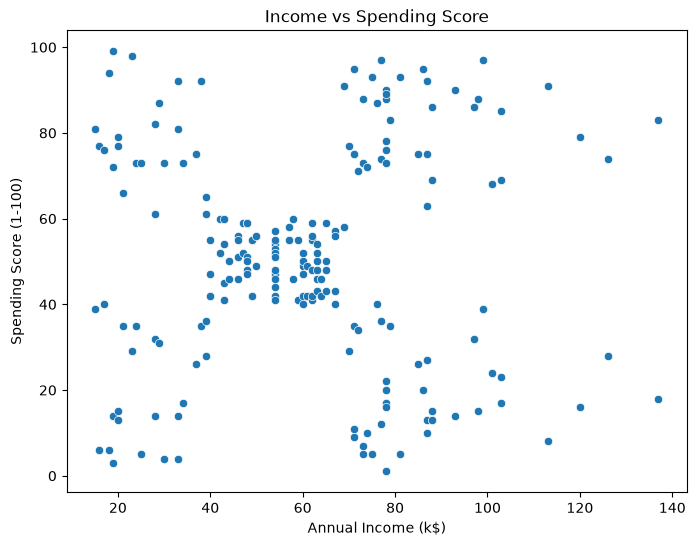

In [6]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    data=df
)

plt.title("Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.show()

In [7]:
from sklearn.cluster import KMeans

In [8]:
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

In [9]:
wcss = []

for i in range(1, 11):
    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

## Determining the Optimal Number of Clusters

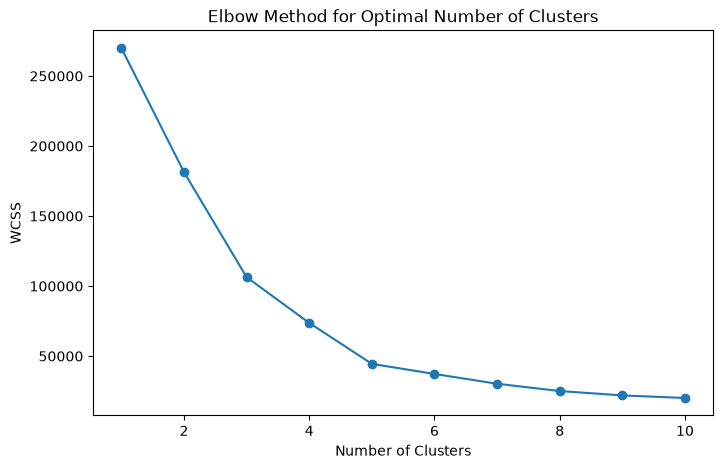

In [10]:
plt.figure(figsize=(8,5))

plt.plot(range(1,11), wcss, marker="o")

plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")

plt.show()

## Customer Segmentation Using K-Means

In [11]:
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X)

df.head()

print("Cluster Centers:")
print(kmeans.cluster_centers_)

Cluster Centers:
[[55.2962963  49.51851852]
 [86.53846154 82.12820513]
 [25.72727273 79.36363636]
 [88.2        17.11428571]
 [26.30434783 20.91304348]]


## Segment Labeling and Color Mapping

In [12]:
segment_names = {
    0: "Average Customers",
    1: "VIP Customers",
    2: "Low Income High Spending",
    3: "High Income Low Spending",
    4: "Low Income Low Spending"
}

df["Segment"] = df["Cluster"].map(segment_names)

segment_colors = {
    "Low Income Low Spending": "#1f77b4",   # Blue
    "Low Income High Spending": "#ff7f0e",  # Orange
    "Average Customers": "#2ca02c",         # Green
    "VIP Customers": "#d62728",             # Red
    "High Income Low Spending": "#9467bd"   # Purple
}

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster,Segment
0,1,Male,19,15,39,4,Low Income Low Spending
1,2,Male,21,15,81,2,Low Income High Spending
2,3,Female,20,16,6,4,Low Income Low Spending
3,4,Female,23,16,77,2,Low Income High Spending
4,5,Female,31,17,40,4,Low Income Low Spending


## Cluster Summary

In [13]:
# %%
print("Customers per Segment:")
print(df["Segment"].value_counts())

Customers per Segment:
Segment
Average Customers           81
VIP Customers               39
High Income Low Spending    35
Low Income Low Spending     23
Low Income High Spending    22
Name: count, dtype: int64


In [14]:
df.groupby("Cluster")[[
    "Annual Income (k$)",
    "Spending Score (1-100)",
    "Age"
]].mean().round(2)

,Annual Income (k$),Spending Score (1-100),Age
Cluster,,,
0,55.30,49.52,42.72
1,86.54,82.13,32.69
2,25.73,79.36,25.27
3,88.20,17.11,41.11
4,26.30,20.91,45.22


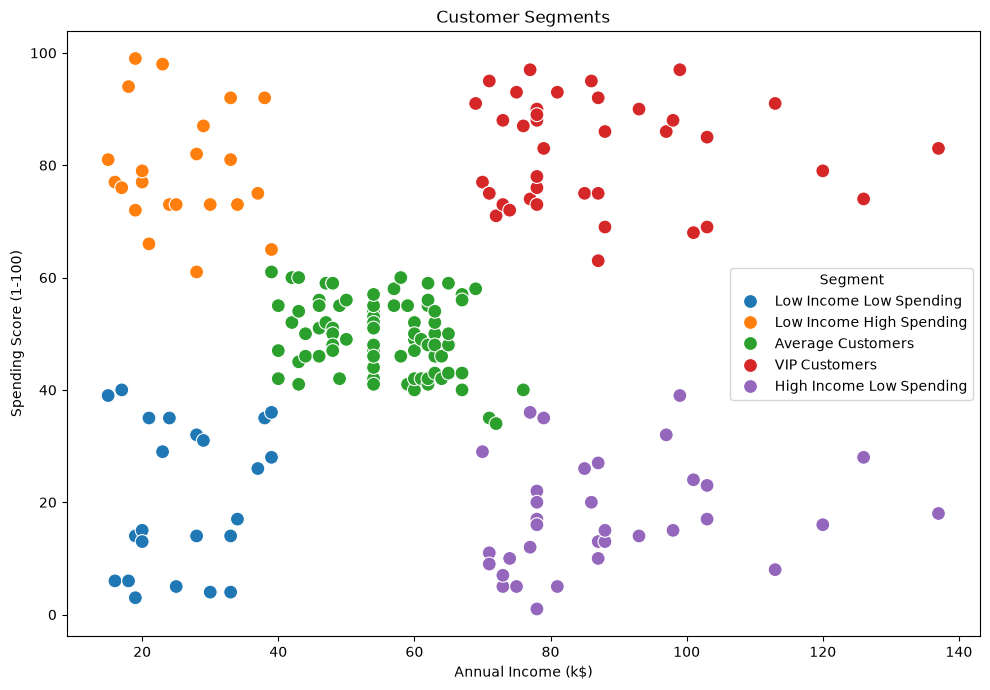

In [15]:
plt.figure(figsize=(10,7))

sns.scatterplot(
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Segment",
    palette=segment_colors,
    data=df,
    s=100
)

plt.title("Customer Segments")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")

plt.tight_layout()

plt.show()

In [16]:
df.to_csv("../data/customer_segments.csv", index=False)

In [17]:
import os

print(os.listdir("../data"))

['customer_segments.csv', 'Mall_Customers.xls']


# Methodology

1. Loaded and explored the dataset.
2. Checked for missing values.
3. Selected Annual Income and Spending Score as clustering features.
4. Applied the Elbow Method to determine the optimal number of clusters.
5. Trained a K-Means model with 5 clusters.
6. Labeled customer segments based on cluster characteristics.
7. Visualized the results using charts and dashboards.

# Business Impact

This customer segmentation model helps SMEs identify high-value customers and design targeted marketing strategies.

Benefits include:

- Better customer retention
- Improved marketing effectiveness
- Increased revenue opportunities
- More efficient allocation of marketing budgets
- Data-driven business decisions

The findings are particularly relevant to SMEs operating in Abuja and other parts of Nigeria.

# Findings

## VIP Customers (Cluster 1)

- Average Income: 86.54k
- Average Spending Score: 82.13
- Average Age: 32.69 years
- These customers generate the highest value for the business.

## High Income Low Spending Customers (Cluster 3)

- Average Income: 88.20k
- Average Spending Score: 17.11
- Average Age: 41.11 years
- Opportunity for targeted premium marketing.

## Low Income High Spending Customers (Cluster 2)

- Average Income: 25.73k
- Average Spending Score: 79.36
- Average Age: 25.27 years
- Highly engaged and responsive to promotions.

## Low Income Low Spending Customers (Cluster 4)

- Average Income: 26.30k
- Average Spending Score: 20.91
- Average Age: 45.22 years
- Budget-conscious segment.

## Average Customers (Cluster 0)

- Average Income: 55.30k
- Average Spending Score: 49.52
- Average Age: 42.72 years
- Largest customer segment.

# Recommendations

## VIP Customers
Provide loyalty rewards and exclusive offers.

## High Income Low Spending Customers
Use personalized campaigns to increase spending.

## Low Income High Spending Customers
Offer discounts and bundle promotions.

## Low Income Low Spending Customers
Promote affordable products and services.

## Average Customers
Use cross-selling and upselling strategies.

# Conclusion

This project successfully applied K-Means clustering to segment customers into five distinct groups based on Annual Income and Spending Score.

The analysis identified VIP Customers, High Income Low Spending Customers, Low Income High Spending Customers, Low Income Low Spending Customers, and Average Customers.

These insights can help SMEs in Abuja and across Nigeria better understand customer behavior, improve customer retention, optimize marketing campaigns, and allocate business resources more effectively.

By using data-driven customer segmentation, businesses can increase profitability and make more informed strategic decisions.

# Dashboard Visuals

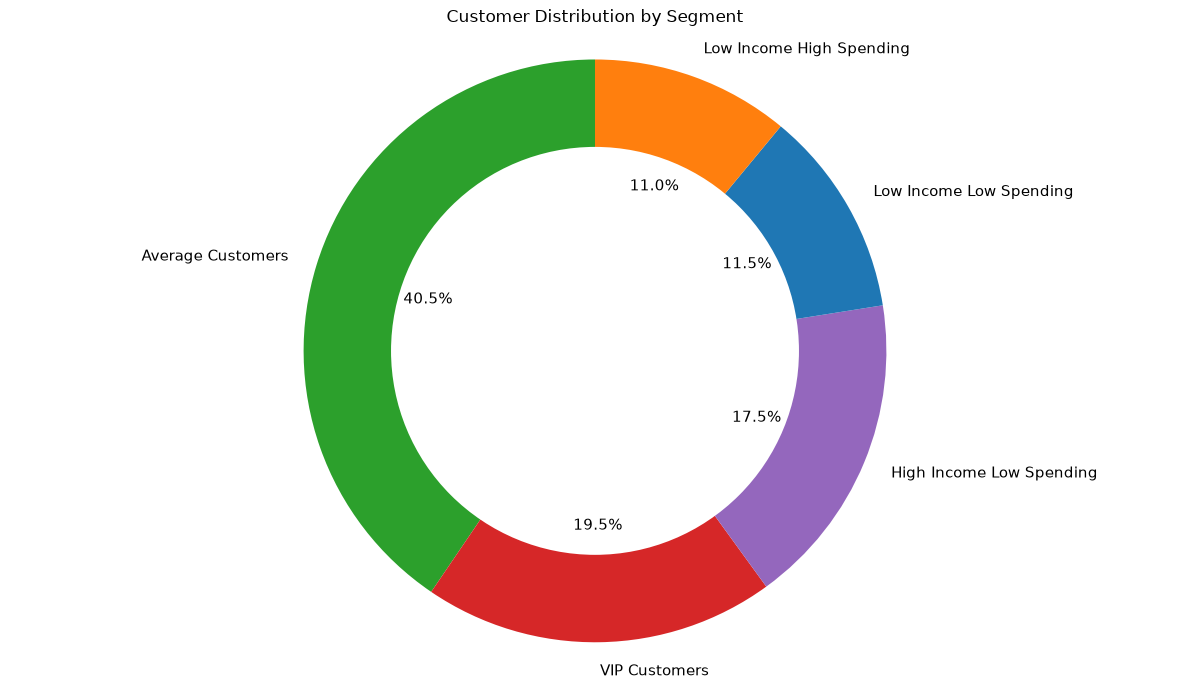

In [18]:
plt.figure(figsize=(12,7))

segment_counts = df["Segment"].value_counts()

segment_pie_colors = [segment_colors[segment] for segment in segment_counts.index]

plt.pie(
    segment_counts,
    labels=segment_counts.index,
    colors=segment_pie_colors,
    autopct="%1.1f%%",
    startangle=90,
    textprops={"fontsize": 11}
)

plt.title("Customer Distribution by Segment")

centre_circle = plt.Circle((0, 0), 0.70, fc="white")
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

plt.axis("equal")

plt.tight_layout()

plt.savefig("../images/customer_distribution.png")

plt.show()

In [19]:
import os

print(os.listdir("../images"))

['customer_distribution.png', 'average_spending.png', 'README.md', 'average_income.png', 'customer_segmentation.png', 'segment_gender.png', '.ignore', 'gender_distribution.png', 'age_distribution.png']


## Customer Segmentation Scatter Plot

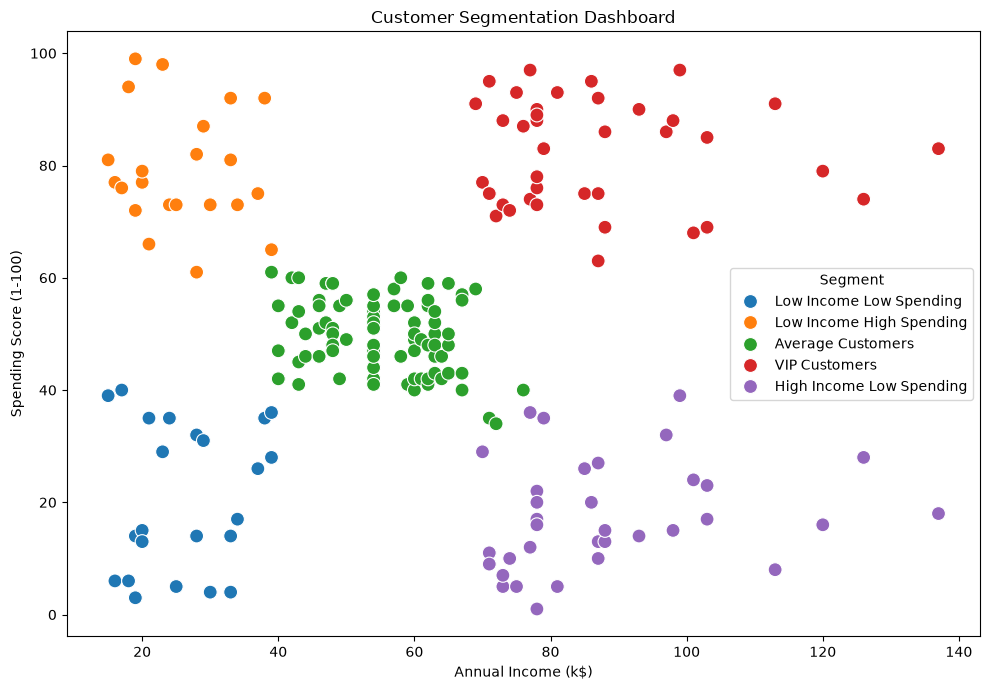

In [20]:
plt.figure(figsize=(10,7))

sns.scatterplot(
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Segment",
    palette=segment_colors,
    data=df,
    s=100
)

plt.title("Customer Segmentation Dashboard")

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.tight_layout()

plt.savefig("../images/customer_segmentation.png")

plt.show()

## Average Income by Segment

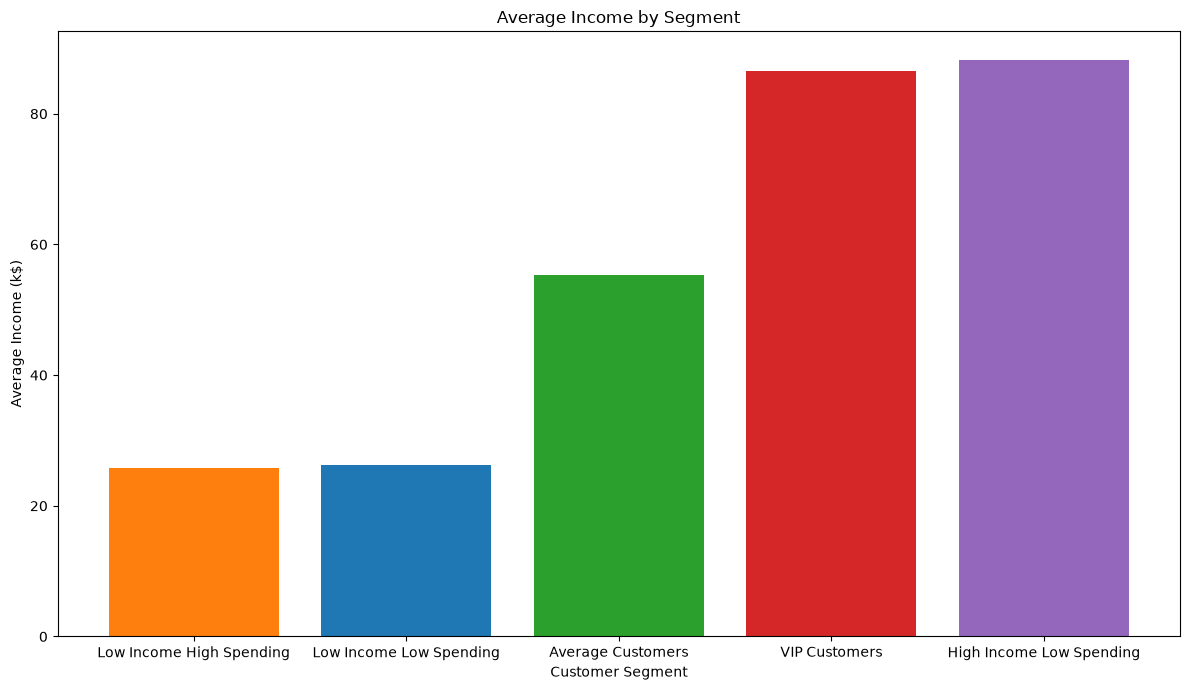

In [21]:
segment_income = df.groupby("Segment")["Annual Income (k$)"].mean()

plt.figure(figsize=(12,7))

segment_income = segment_income.sort_values()

plt.bar(
    segment_income.index,
    segment_income.values,
    color=[segment_colors[x] for x in segment_income.index]
)

plt.title("Average Income by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Income (k$)")
plt.tight_layout()

plt.savefig("../images/average_income.png")

plt.show()

## Average Spending Score by Segment

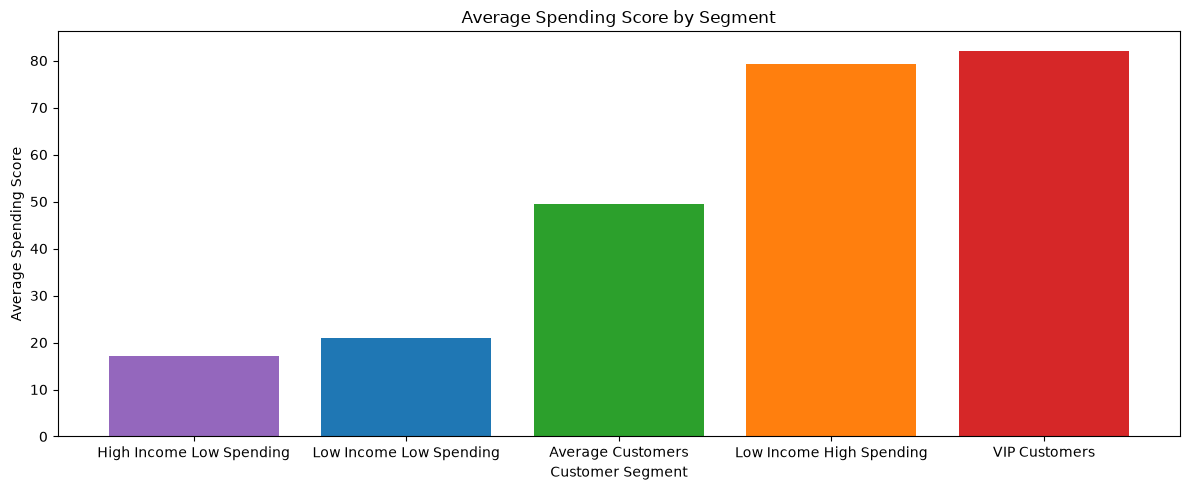

In [22]:
segment_spending = df.groupby("Segment")["Spending Score (1-100)"].mean()

plt.figure(figsize=(12,5))

segment_spending = segment_spending.sort_values()

plt.bar(
    segment_spending.index,
    segment_spending.values,
    color=[segment_colors[x] for x in segment_spending.index]
)
plt.title("Average Spending Score by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Spending Score")
plt.tight_layout()

plt.savefig("../images/average_spending.png")

plt.show()

/tmp/ipykernel_353527/97135999.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


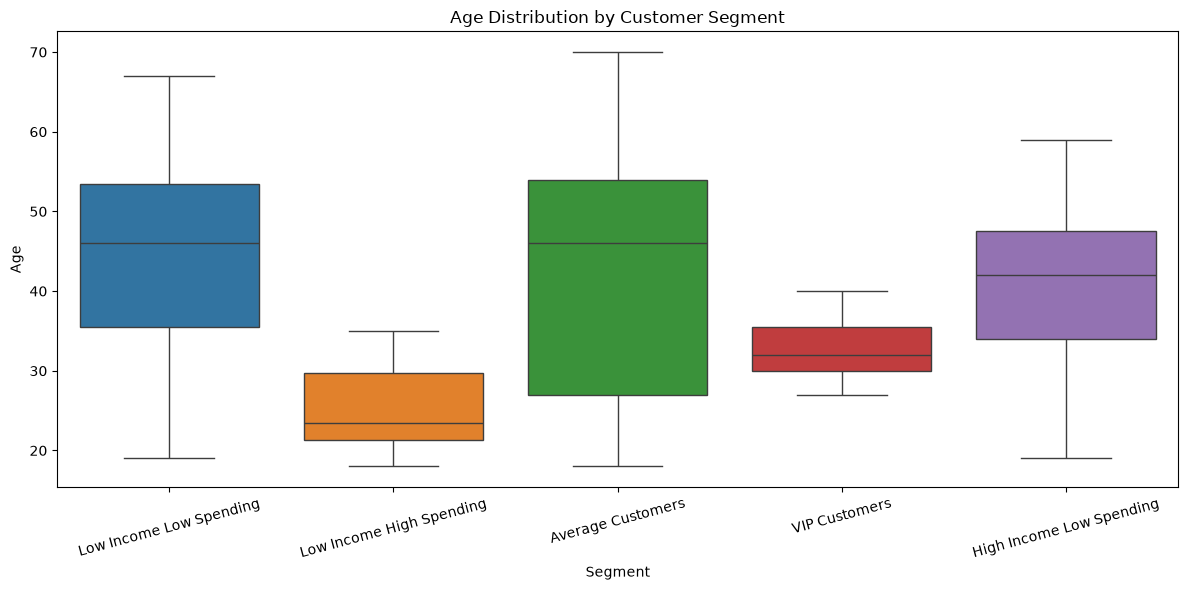

In [23]:
plt.figure(figsize=(12,6))

sns.boxplot(
    x="Segment",
    y="Age",
    data=df,
    palette=segment_colors
)

plt.title("Age Distribution by Customer Segment")
plt.xticks(rotation=15)

plt.tight_layout()

plt.savefig("../images/age_distribution.png")

plt.show()

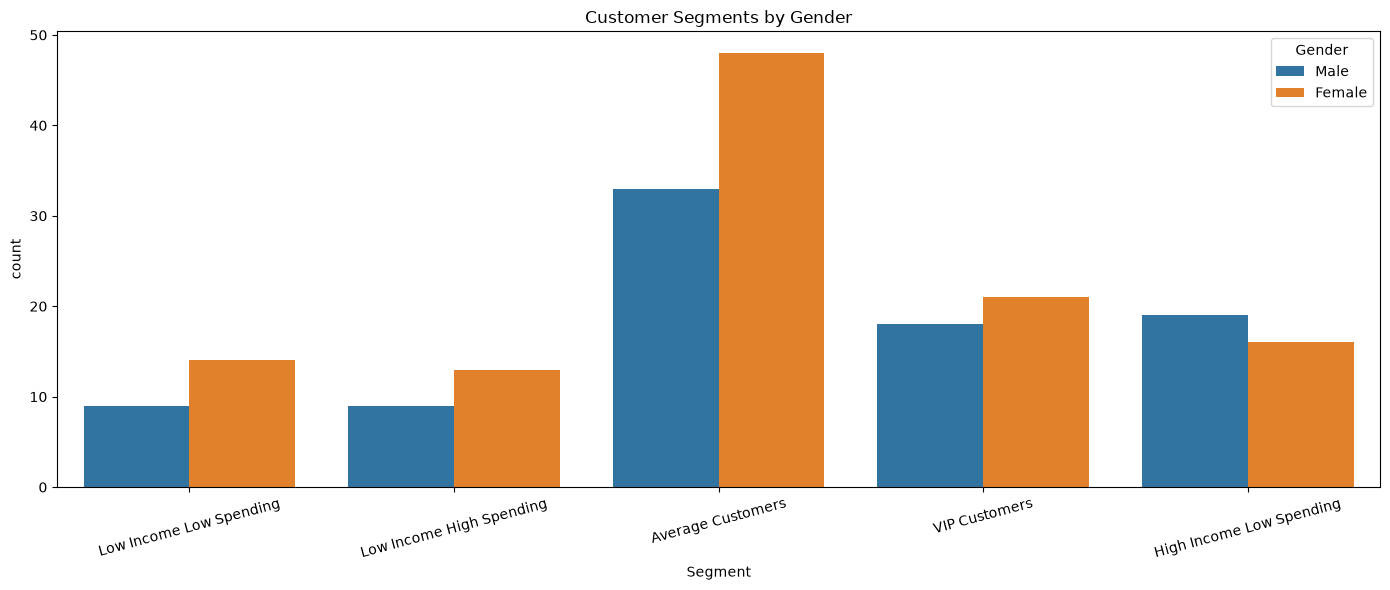

In [24]:
plt.figure(figsize=(14,6))

sns.countplot(
    x="Segment",
    hue="Gender",
    data=df
)

plt.title("Customer Segments by Gender")

plt.xticks(rotation=15)

plt.tight_layout()

plt.savefig("../images/segment_gender.png")

plt.show()

## Gender Distribution

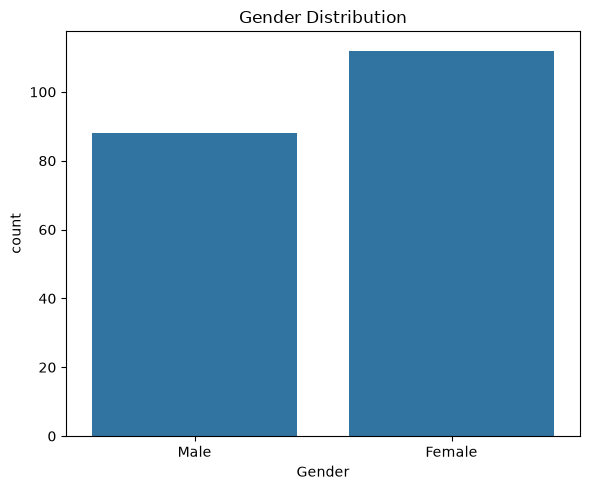

In [25]:
plt.figure(figsize=(6,5))

sns.countplot(
    x="Gender",
    data=df
)

plt.title("Gender Distribution")

plt.tight_layout()

plt.savefig("../images/gender_distribution.png")

plt.show()

## Final Verification

In [26]:
import os

print(os.listdir("../images"))

['customer_distribution.png', 'average_spending.png', 'README.md', 'average_income.png', 'customer_segmentation.png', 'segment_gender.png', '.ignore', 'gender_distribution.png', 'age_distribution.png']
